# Chirp explorer

Change the parameters below, then select **Run All** to see how they affect the waveform, FFT, and spectrogram. Frequencies at or above half the sampling frequency can alias.

### Contents

- [Generate the chirp](#generate-the-chirp)
- [Waveform](#waveform)
- [FFT](#fft)
- [Spectrogram](#spectrogram)

In [1]:
import os
import sys
from pathlib import Path

# Add native libraries when a Windows conda kernel is not activated.
library_bin = Path(sys.prefix) / "Library" / "bin"
if sys.platform == "win32" and (Path(sys.prefix) / "conda-meta").is_dir() and library_bin.is_dir():
    os.environ["PATH"] = str(library_bin) + os.pathsep + os.environ.get("PATH", "")

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, spectrogram

# Change these values and run all cells again.
duration = 0.01  # pulse duration in seconds
fs = 20000       # sampling frequency in samples per second
f0 = 500         # starting frequency in Hz
f1 = 3500        # ending frequency in Hz

## Generate the chirp

The instantaneous frequency changes linearly from `f0` to `f1` over `duration` seconds.

In [2]:
if duration <= 0 or fs <= 0 or f0 < 0 or f1 < 0:
    raise ValueError("Duration and sampling frequency must be positive; frequencies must be non-negative.")

n = round(duration * fs)
if n < 20:
    raise ValueError("Increase duration or sampling frequency to produce at least 20 samples.")

if max(f0, f1) >= fs / 2:
    print(f"Warning: frequencies at or above the Nyquist frequency ({fs / 2:g} Hz) can alias.")

# Sample the chirp at intervals of 1/fs seconds.
t = np.arange(n) / fs
x = chirp(t, f0=f0, t1=duration, f1=f1, method="linear")
print(f"Samples: {n}; FFT bin spacing: {fs / n:g} Hz")

Samples: 200; FFT bin spacing: 100 Hz


## Waveform

The time-domain plot shows how the oscillations change during the pulse.

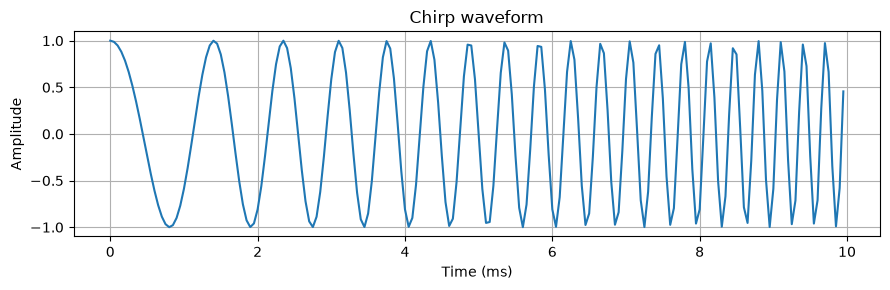

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t * 1000, x)
ax.set(title="Chirp waveform", xlabel="Time (ms)", ylabel="Amplitude")
ax.grid(True)
fig.tight_layout()
plt.show()

## FFT

The FFT shows frequency content over the whole pulse, but not when each frequency occurs.

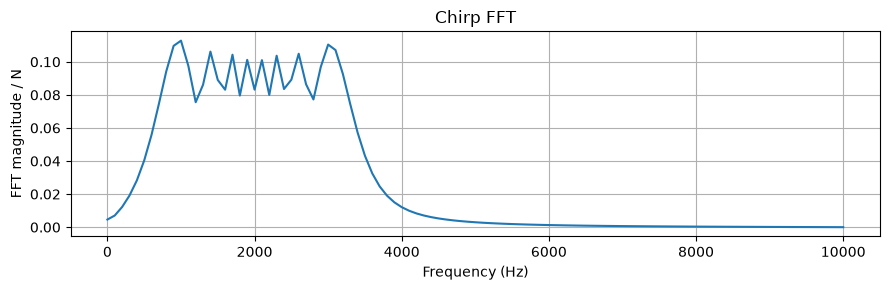

In [4]:
# Find the non-negative frequency bins and their FFT magnitudes.
frequencies = np.fft.rfftfreq(n, d=1 / fs)
fft_magnitude = np.abs(np.fft.rfft(x)) / n

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(frequencies, fft_magnitude)
ax.set(title="Chirp FFT", xlabel="Frequency (Hz)", ylabel="FFT magnitude / N")
ax.grid(True)
fig.tight_layout()
plt.show()

## Spectrogram

Overlapping windows reveal how frequency changes with time. The window length is 20% of the pulse duration: it trades time resolution for frequency resolution. Colors represent magnitude in dB relative to the peak.

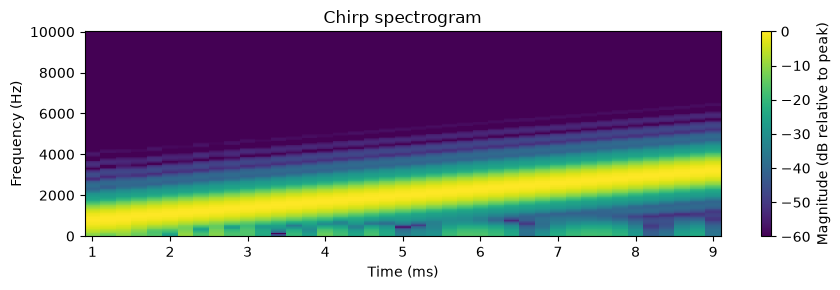

In [5]:
# Analyze overlapping windows of the pulse.
window_samples = max(4, round(n * 0.2))
freq, times, magnitude = spectrogram(
    x, fs=fs, window="hann", nperseg=window_samples,
    noverlap=window_samples * 9 // 10, nfft=max(512, window_samples),
    scaling="spectrum", mode="magnitude",
)
# Convert magnitude to dB relative to the strongest bin.
magnitude_db = 20 * np.log10(np.maximum(magnitude / max(magnitude.max(), 1e-12), 1e-6))

fig, ax = plt.subplots(figsize=(9, 3))
image = ax.pcolormesh(times * 1000, freq, magnitude_db, shading="auto", vmin=-60, vmax=0)
ax.set(title="Chirp spectrogram", xlabel="Time (ms)", ylabel="Frequency (Hz)")
fig.colorbar(image, ax=ax, label="Magnitude (dB relative to peak)")
fig.tight_layout()
plt.show()